
# **Aprendizado de Máquina**




## Exemplo Supervisionado (k-NN com Iris)

O parâmetro **k** no k-Nearest Neighbors indica quantos 'vizinhos' mais próximos serão considerados para a classificação de um novo dado. Por exemplo:
* Se ***k=1***, o algoritmo olha apenas para o vizinho mais próximo. Isso pode causar classificações sensíveis a ruídos, pois pode considerar um exemplo estranho e errar.

* Se ***k=5***, o algoritmo considera os 5 vizinhos mais próximos e decide com base na maioria, tornando a classificação mais robusta, porém menos sensível a detalhes finos. Ajustar **k** pode melhorar ou piorar o modelo, dependendo do problema e dos dados."

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.2, random_state=42
)

model = KNeighborsClassifier(n_neighbors=1) #Modificando o valor de n_neighbors você muda o número de vizinhos considerados, e isso impacta diretamente a acurácia que será calculada.
model.fit(X_train, y_train)

print("Acurácia:", accuracy_score(y_test, model.predict(X_test)))


Acurácia: 1.0


Observem a acurácia obtida. Se diminuirmos **k**, pode acontecer do modelo 'se adaptar demais' e errar para dados novos (overfitting). Se aumentarmos **k**, o modelo pode ser muito generalista e perder detalhes importantes (underfitting). Vamos experimentar esses valores e ver os efeitos

#Árvore de Decisão (Supervisionado)
Código para classificar Iris com árvore e visualizar


Acurácia: 1.0


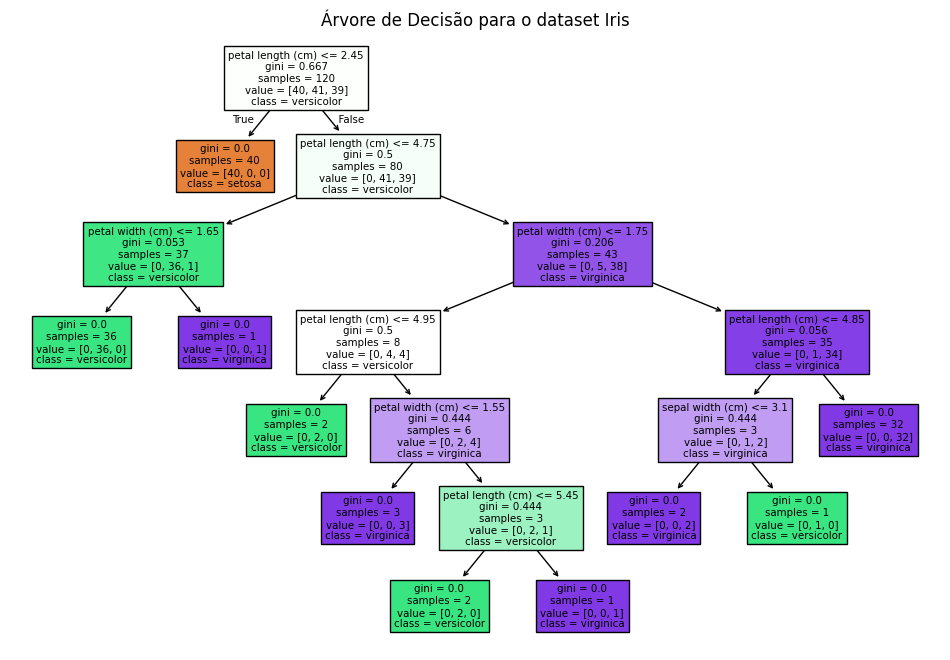

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# Carregar dados
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.2, random_state=42)

# Modelo
tree_clf = DecisionTreeClassifier(random_state=42)
tree_clf.fit(X_train, y_train)

# Avaliação
print("Acurácia:", tree_clf.score(X_test, y_test))

# Visualizar árvore
plt.figure(figsize=(12,8))
plot_tree(tree_clf, filled=True, feature_names=iris.feature_names, class_names=iris.target_names)
plt.title("Árvore de Decisão para o dataset Iris")
plt.show()


## Árvores de Decisão (inspirado em Géron)
Interpretação visual: cada cor na árvore representa uma espécie de flor, mostrando quais medidas foram decisivas

[Text(0.5, 0.9166666666666666, 'petal length (cm) <= 2.45\ngini = 0.667\nsamples = 150\nvalue = [50, 50, 50]\nclass = setosa'),
 Text(0.4230769230769231, 0.75, 'gini = 0.0\nsamples = 50\nvalue = [50, 0, 0]\nclass = setosa'),
 Text(0.46153846153846156, 0.8333333333333333, 'True  '),
 Text(0.5769230769230769, 0.75, 'petal width (cm) <= 1.75\ngini = 0.5\nsamples = 100\nvalue = [0, 50, 50]\nclass = versicolor'),
 Text(0.5384615384615384, 0.8333333333333333, '  False'),
 Text(0.3076923076923077, 0.5833333333333334, 'petal length (cm) <= 4.95\ngini = 0.168\nsamples = 54\nvalue = [0, 49, 5]\nclass = versicolor'),
 Text(0.15384615384615385, 0.4166666666666667, 'petal width (cm) <= 1.65\ngini = 0.041\nsamples = 48\nvalue = [0, 47, 1]\nclass = versicolor'),
 Text(0.07692307692307693, 0.25, 'gini = 0.0\nsamples = 47\nvalue = [0, 47, 0]\nclass = versicolor'),
 Text(0.23076923076923078, 0.25, 'gini = 0.0\nsamples = 1\nvalue = [0, 0, 1]\nclass = virginica'),
 Text(0.46153846153846156, 0.416666666666

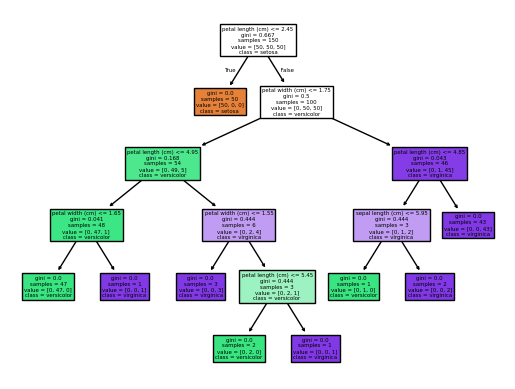

In [ ]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree
iris = load_iris()
tree_clf = DecisionTreeClassifier(random_state=42)
tree_clf.fit(iris.data, iris.target)
plot_tree(tree_clf, filled=True, feature_names=iris.feature_names, class_names=iris.target_names)


##Regressão Logística

###O que é Regressão Logística?
* A regressão logística é um modelo de aprendizado supervisionado, amplamente utilizado para classificação.

* Seu objetivo é prever a probabilidade de uma amostra pertencer a uma determinada classe, baseando-se em variáveis explicativas (features).

* No contexto da base Iris, ela é utilizada para prever qual espécie de flor cada amostra representa (setosa, versicolor ou virginica).

###Como o modelo aprende?
* Durante o treinamento, o modelo ajusta seus coeficientes internos para minimizar uma função de custo chamada “log loss”.

* Para cada exemplo do conjunto de treino, o modelo compara sua predição com o rótulo verdadeiro e ajusta os coeficientes para aumentar a precisão global.

* Esse ajuste é feito por algoritmos de otimização, como o gradiente descendente.

* O modelo é treinado usando apenas os dados de treino, sem acesso aos dados de validação ou teste para evitar sobreajuste (overfitting).

###Processo passo a passo:
1. Recepção dos dados: Cada amostra contém 4 características (comprimento/peso da pétala e sépala).

2. Inicialização dos coeficientes/random weights: O modelo começa com pesos aleatórios.

3. Cálculo das predições: Para cada amostra, estima uma probabilidade de classe usando uma função logística (sigmoide).

4. Avaliação do erro (função de custo): Calcula o erro entre a predição e o rótulo verdadeiro.

5. Otimização: Ajusta os pesos para minimizar o erro.

6. Repetição: Repete esse ciclo de predição-erro-ajuste até convergir.

###Avaliação do modelo:
* Após o treinamento, são feitas previsões para os conjuntos de validação e teste.

* As métricas usadas para avaliar o desempenho incluem a acurácia (proporção de acertos) e matriz de confusão (para visualizar erros por classe).

* Se a acurácia no conjunto de validação e teste for similar à acurácia de treino, o modelo generaliza bem.

* Se a acurácia de treino for muito maior que a de validação/teste, pode ser sinal de sobreajuste.



In [ ]:
# Importações
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
import pandas as pd

# 1. Carregar base Iris
iris = load_iris()
X = iris.data
y = iris.target

# 2. Dividir em treino (70%), validação (15%), teste (15%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

# 3. Treinar modelo de regressão logística
model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)

# 4. Previsões
y_pred_train = model.predict(X_train)
y_pred_val = model.predict(X_val)
y_pred_test = model.predict(X_test)

# 5. Métricas de desempenho
acc_train = accuracy_score(y_train, y_pred_train)
acc_val = accuracy_score(y_val, y_pred_val)
acc_test = accuracy_score(y_test, y_pred_test)

# 6. Exibir resultados e matriz de confusão
print(f"Acurácia Treino: {acc_train:.2f}")
print(f"Acurácia Validação: {acc_val:.2f}")
print(f"Acurácia Teste: {acc_test:.2f}")

print("Matriz de Confusão - Teste:")
print(confusion_matrix(y_test, y_pred_test))

# Extra: Exibir primeiras linhas do DataFrame
df = pd.DataFrame(X, columns=iris.feature_names)
df['target'] = y
df.head()


Acurácia Treino: 0.97
Acurácia Validação: 0.86
Acurácia Teste: 1.00
Matriz de Confusão - Teste:
[[7 0 0]
 [0 8 0]
 [0 0 8]]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Analise:
* Há diferença relevante entre acurácias de treino, validação e teste?

* Experimentar alterar parâmetros do modelo (ex: aumentar métrica de iterações, usar regularização)

* O modelo tende a overfitting, underfitting ou foi bem ajustado?

* O que representa a matriz de confusão?

* Tente trocar por outro classificador (“DecisionTreeClassifier” ou “KNeighborsClassifier”) e compare!



---

# *Exemplo Não Supervisionado (k-Means com Iris)*
O parâmetro k no k-Means significa quantos grupos o algoritmo deverá formar. Por exemplo:


* Com **k=2**, o algoritmo criará apenas dois grupos, que podem misturar categorias diferentes.

* Com **k=4**, terá mais grupos, dividindo os dados em categorias mais específicas.
Escolher **k** é importante e não existe uma regra única — normalmente testamos vários valores para encontrar um que faça sentido para nosso objetivo.

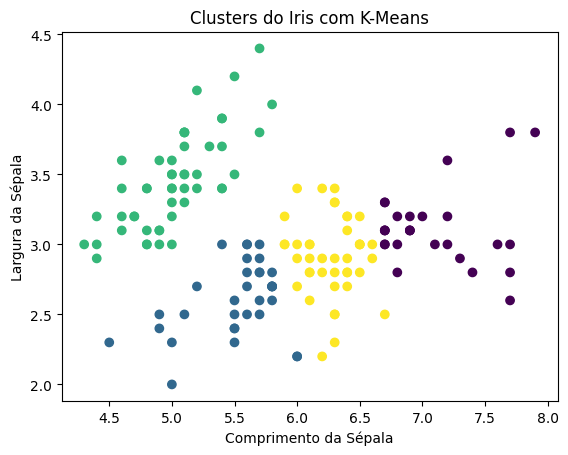

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

X = iris.data[:, :2]  # duas features para visualizar
kmeans = KMeans(n_clusters=4, random_state=42) # número de clusters é definido na criação do objeto KMeans
kmeans.fit(X)

plt.scatter(X[:,0], X[:,1], c=kmeans.labels_, cmap="viridis")
plt.xlabel("Comprimento da Sépala")
plt.ylabel("Largura da Sépala")
plt.title("Clusters do Iris com K-Means")
plt.show()


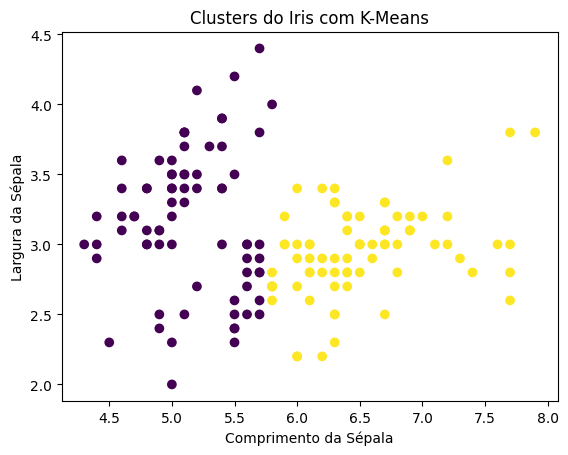

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

X = iris.data[:, :2]  # duas features para visualizar
kmeans = KMeans(n_clusters=2, random_state=42) # número de clusters é definido na criação do objeto KMeans
kmeans.fit(X)

plt.scatter(X[:,0], X[:,1], c=kmeans.labels_, cmap="viridis")
plt.xlabel("Comprimento da Sépala")
plt.ylabel("Largura da Sépala")
plt.title("Clusters do Iris com K-Means")
plt.show()

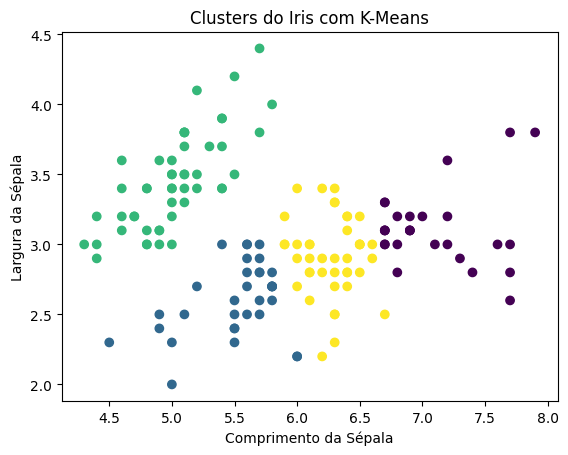

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

X = iris.data[:, :2]  # duas features para visualizar
kmeans = KMeans(n_clusters=4, random_state=42) # número de clusters é definido na criação do objeto KMeans
kmeans.fit(X)

plt.scatter(X[:,0], X[:,1], c=kmeans.labels_, cmap="viridis")
plt.xlabel("Comprimento da Sépala")
plt.ylabel("Largura da Sépala")
plt.title("Clusters do Iris com K-Means")
plt.show()

No gráfico, cada ponto tem uma cor que indica a qual cluster ele pertence. Assim, você pode ver como os dados foram divididos. Quando o **k** muda, as cores mudam e as divisões também, o que demonstra a influência do parâmetro na saída do modelo

## PCA (Análise de Componentes Principais) (Não Supervisionado)
Código para redução dimensional do Iris de 4 para 2 dimensões

Observe: como a distribuição das espécies fica visualmente clara mesmo com menos dimensões


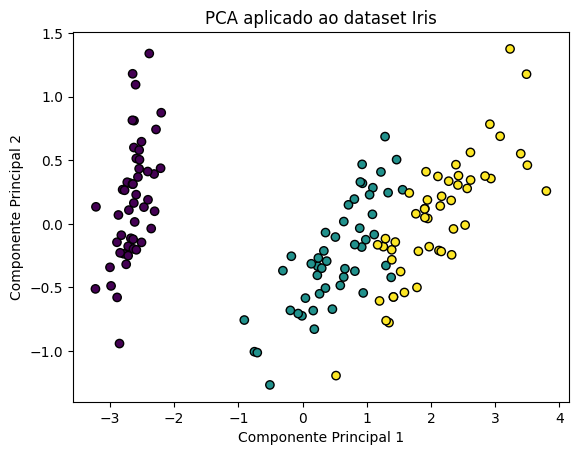

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_reduced = pca.fit_transform(iris.data)

plt.scatter(X_reduced[:, 0], X_reduced[:, 1], c=iris.target, cmap='viridis', edgecolor='k')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.title('PCA aplicado ao dataset Iris')
plt.show()


In [ ]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
iris = load_iris()
tree_clf = DecisionTreeClassifier(random_state=42)
tree_clf.fit(iris.data, iris.target)
pred = tree_clf.predict([iris.data[0]])
print("Exemplo supervisionado: previsão da espécie:", iris.target_names[pred][0])


Exemplo supervisionado: previsão da espécie: setosa


In [ ]:
# k-Means sem usar labels reais
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3, random_state=42)
labels = kmeans.fit_predict(iris.data)
print("Exemplo não supervisionado: clusters encontrados:", set(labels))


Exemplo não supervisionado: clusters encontrados: {np.int32(0), np.int32(1), np.int32(2)}


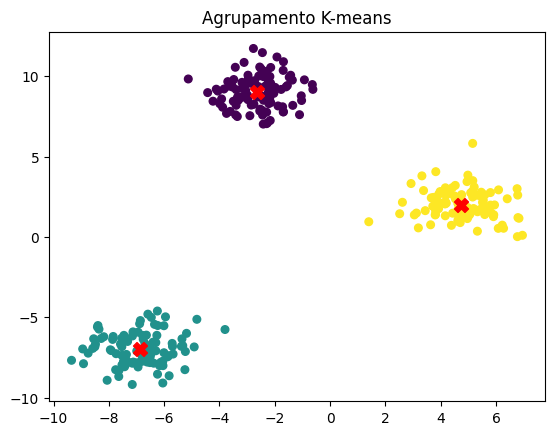

In [ ]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Gerando dados sintéticos em 2D
X, y = make_blobs(n_samples=300, centers=3, random_state=42)

# Treinando o modelo K-means (3 clusters)
kmeans = KMeans(n_clusters=3)
kmeans.fit(X)
labels = kmeans.labels_
centers = kmeans.cluster_centers_

# Visualização dos clusters
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=30)
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=100, marker='X')
plt.title('Agrupamento K-means')
plt.show()
